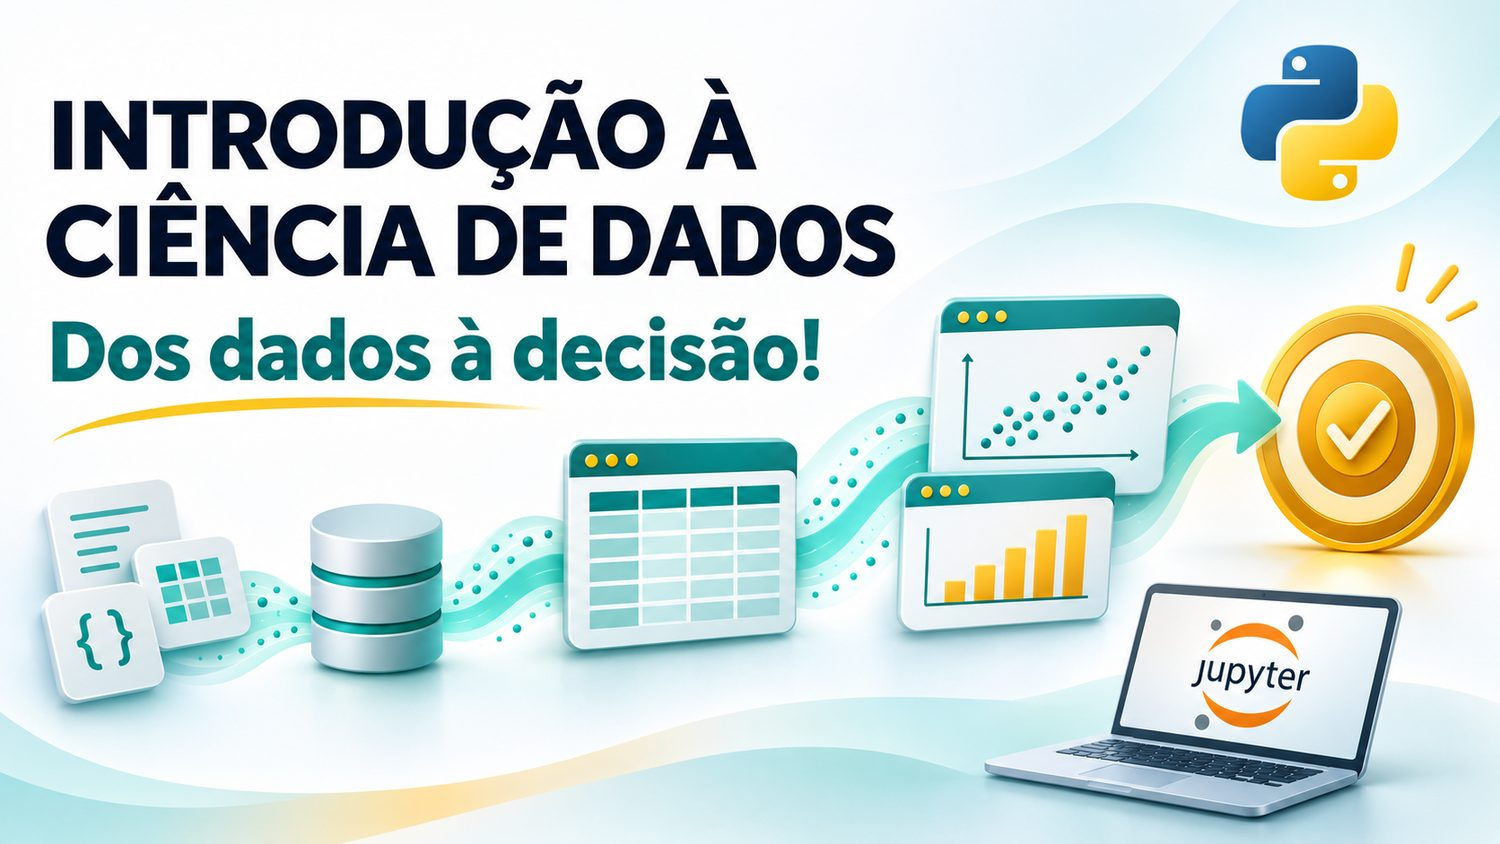

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_8_comunicar_e_usar_com_responsabilidade/03_Comunicar_a_Incerteza.ipynb)

# Capítulo 3 – Comunicar a incerteza

«A lista apanha 10 das 22 desistências.» Apanharia 10 se o teste tivesse sido feito com outros formandos? Qualquer número calculado com uma amostra vem acompanhado de uma margem, e escondê-la é dar ao leitor uma certeza que não temos. Este capítulo mostra como medir essa margem com poucas linhas de código e, sobretudo, como dizê-la a quem não é da área.

> **Objetivos:** perceber porque uma métrica é uma estimativa; calcular um intervalo por *bootstrap* para qualquer métrica; ver o efeito do tamanho da amostra; comparar dois modelos tendo em conta a incerteza; desconfiar de classificações feitas com grupos pequenos; explicar o que significa uma probabilidade prevista; apresentar a incerteza em texto e em gráfico; saber o que um intervalo não cobre.

**Pré-requisitos:** capítulos 1 e 2; o capítulo 5 do módulo 1 (amostragem e intervalos de confiança) e o capítulo 7 do módulo 6 (amostras bootstrap).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_formandos(n=6000, semente=97):
    """Gera formandos de um centro de formação profissional fictício (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    zona = rng.choice(["urbana", "rural"], n, p=[0.78, 0.22])
    rural = zona == "rural"
    idade = rng.normal(34, 10, n).clip(18, 62).round()
    escolaridade = rng.choice(["básico", "secundário", "superior"], n, p=[0.3, 0.5, 0.2])
    empregado = rng.random(n) < 0.45
    distancia = np.where(rural, rng.gamma(4.0, 6.0, n), rng.gamma(2.0, 2.5, n)).clip(0.5, 70).round(1)
    computador = rng.random(n) < np.where(rural, 0.62, 0.84)
    nota_inicial = (rng.normal(58, 15, n) + 6 * (escolaridade == "superior") - 5 * (escolaridade == "básico")).clip(5, 100).round()
    transporte_irregular = rural & (rng.random(n) < 0.30)                     # não fica registado em lado nenhum
    faltas = rng.poisson(np.clip(1.0 + 0.9 * empregado + 0.035 * distancia - 0.012 * (nota_inicial - 58) + 0.6 * ~computador, 0.15, None))
    z = (-2.95 + 0.42 * faltas + 0.55 * empregado - 0.022 * (nota_inicial - 58) + 0.55 * ~computador + 0.012 * distancia + 1.7 * transporte_irregular)
    desistiu = rng.random(n) < 1 / (1 + np.exp(-z))
    return pd.DataFrame({"idade": idade, "zona": zona, "escolaridade": escolaridade, "empregado": empregado, "distancia_km": distancia,
                         "tem_computador": computador, "nota_inicial": nota_inicial, "faltas_primeiro_mes": faltas, "desistiu": desistiu})


formandos = gerar_formandos()
formandos.head()

,idade,zona,escolaridade,empregado,distancia_km,tem_computador,nota_inicial,faltas_primeiro_mes,desistiu
0,44.0,urbana,secundário,True,3.3,True,58.0,3,False
1,44.0,urbana,secundário,True,4.5,False,56.0,3,False
2,40.0,urbana,secundário,True,1.8,True,79.0,0,False
3,54.0,rural,básico,True,33.4,False,65.0,6,True
4,47.0,urbana,secundário,True,3.8,True,40.0,0,False


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numericas = ["idade", "distancia_km", "nota_inicial", "faltas_primeiro_mes", "empregado", "tem_computador"]
nominais = ["zona", "escolaridade"]
atributos = numericas + nominais
desenvolvimento, teste = train_test_split(formandos, test_size=0.3, random_state=0, stratify=formandos["desistiu"])
modelo = make_pipeline(ColumnTransformer([("num", StandardScaler(), numericas), ("cat", OneHotEncoder(), nominais)]), LogisticRegression(max_iter=2000))
modelo.fit(desenvolvimento[atributos], desenvolvimento["desistiu"])
risco = modelo.predict_proba(teste[atributos])[:, 1]
real = teste["desistiu"].to_numpy()

## Uma métrica é uma estimativa

No capítulo 1 calculámos, com 1 800 formandos de teste, quantas desistências a lista apanha quando a equipa acompanha o quinto de maior risco.

In [4]:
def apanhados_por_100(risco, real, capacidade=0.20):
    """Em cada 100 formandos, quantos dos que desistem estão entre os acompanhados."""
    acompanhado = risco >= np.quantile(risco, 1 - capacidade)
    return (acompanhado & real).sum() / len(real) * 100


print(f"Desistências apanhadas em cada 100 formandos: {apanhados_por_100(risco, real):.1f}")

Desistências apanhadas em cada 100 formandos: 10.4


Esses 1 800 formandos são uma **amostra** dos formandos a quem a lista vai ser aplicada. Com outros 1 800, o número seria outro. A pergunta é: **quão diferente?**

Não podemos ir buscar outros 1 800. Podemos fazer o que fizemos no módulo 6 para construir florestas: **reamostrar os que temos**, com reposição, e ver quanto o resultado varia.

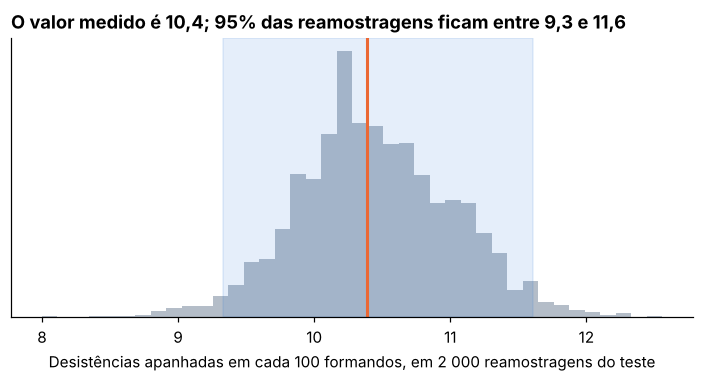

In [5]:
def bootstrap(metrica, *colunas, repeticoes=2000, semente=0):
    """Recalcula a métrica em amostras bootstrap das linhas. Devolve todos os valores obtidos."""
    rng = np.random.default_rng(semente)
    n = len(colunas[0])
    valores = []
    for _ in range(repeticoes):
        posicoes = rng.integers(0, n, n)                          # as mesmas linhas em todas as colunas
        valores.append(metrica(*(coluna[posicoes] for coluna in colunas)))
    return np.array(valores)


valores = bootstrap(apanhados_por_100, risco, real)
inferior, superior = np.percentile(valores, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(8, 3.3))
ax.hist(valores, bins=40, color=CINZA)
ax.axvspan(inferior, superior, color=AZUL, alpha=0.12)
ax.axvline(apanhados_por_100(risco, real), color=LARANJA, lw=2)
ax.set_yticks([])
ax.set_xlabel("Desistências apanhadas em cada 100 formandos, em 2 000 reamostragens do teste")
ax.set_title(f"O valor medido é {apanhados_por_100(risco, real):.1f}; 95% das reamostragens ficam entre {inferior:.1f} e {superior:.1f}".replace(".", ","))
plt.show()

O histograma mostra os valores que a métrica toma em 2 000 amostras bootstrap. A zona azul contém 95% deles: é um **intervalo de confiança a 95%**, obtido pelo método dos percentis.

A leitura prática: os dados são compatíveis com a lista apanhar **entre 9 e 12** desistências em cada 100 formandos. Dizer «10,4» sugere uma precisão que não temos; dizer «cerca de 10, mais ou menos 1» é mais verdadeiro e igualmente útil.

A função `bootstrap` não sabe nada sobre a métrica: recebe uma função e reamostra as linhas. Serve para a sensibilidade, a AUC, o erro absoluto médio, uma mediana, a diferença entre dois grupos. É a forma mais simples de pôr uma margem em **qualquer** número.

## Menos dados, mais incerteza

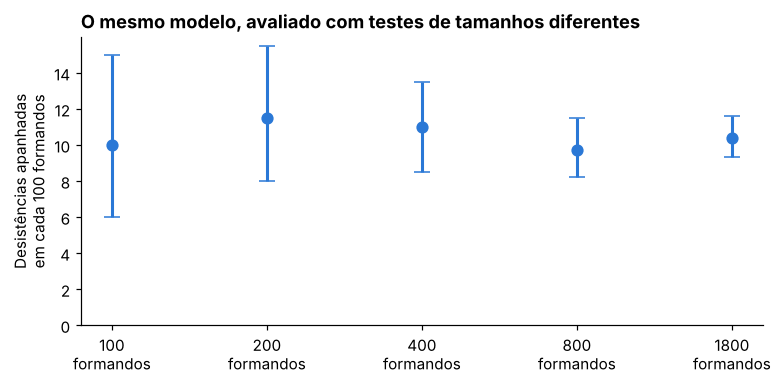

In [6]:
rng = np.random.default_rng(1)
linhas = []
for n in [100, 200, 400, 800, 1800]:
    posicoes = rng.choice(len(real), n, replace=False)
    v = bootstrap(apanhados_por_100, risco[posicoes], real[posicoes], repeticoes=1000)
    linhas.append({"n": n, "medido": apanhados_por_100(risco[posicoes], real[posicoes]), "inferior": np.percentile(v, 2.5), "superior": np.percentile(v, 97.5)})
por_tamanho = pd.DataFrame(linhas)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.errorbar(range(len(por_tamanho)), por_tamanho["medido"], yerr=[por_tamanho["medido"] - por_tamanho["inferior"], por_tamanho["superior"] - por_tamanho["medido"]],
            fmt="o", color=AZUL, ecolor=AZUL, elinewidth=2, capsize=5, markersize=7)
ax.set_xticks(range(len(por_tamanho)), [f"{n}\nformandos" for n in por_tamanho["n"]])
ax.set_ylim(0, None)
ax.set_ylabel("Desistências apanhadas\nem cada 100 formandos")
ax.set_title("O mesmo modelo, avaliado com testes de tamanhos diferentes")
plt.show()

O ponto é o valor medido; a barra é o intervalo a 95%. Com 100 formandos de teste, o resultado podia ser quase qualquer coisa entre 6 e 15. Com 1 800, a margem é de cerca de um caso para cada lado.

A largura do intervalo diminui com a **raiz quadrada** do tamanho da amostra: para reduzir a margem a metade são precisos quatro vezes mais dados. Um relatório que apresenta uma métrica calculada em 100 casos, sem margem, está a apresentar ruído como se fosse resultado.

## O modelo é melhor do que a regra simples?

No capítulo 1, a lista do modelo apanhava 10 desistências em cada 100 formandos, e a regra «acompanhar quem mais falta» apanhava 9. O modelo é melhor?

Para comparar duas formas de escolher **nos mesmos formandos**, reamostra-se e calcula-se a **diferença** em cada amostra.

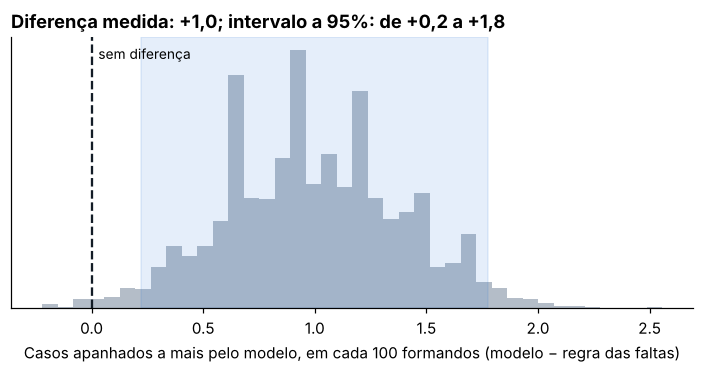

Reamostragens em que o modelo apanha mais casos do que a regra: 99%


In [7]:
faltas = teste["faltas_primeiro_mes"].to_numpy() + np.random.default_rng(0).random(len(teste)) * 0.01      # desempate ao acaso


def diferenca(risco, faltas, real):
    return apanhados_por_100(risco, real) - apanhados_por_100(faltas, real)


d = bootstrap(diferenca, risco, faltas, real)
d_inf, d_sup = np.percentile(d, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(d, bins=40, color=CINZA)
ax.axvline(0, color=TINTA, lw=1.5, ls="--")
ax.axvspan(d_inf, d_sup, color=AZUL, alpha=0.12)
ax.text(0.03, ax.get_ylim()[1] * 0.92, "sem diferença", fontsize=9)
ax.set_yticks([])
ax.set_xlabel("Casos apanhados a mais pelo modelo, em cada 100 formandos (modelo − regra das faltas)")
ax.set_title(f"Diferença medida: {diferenca(risco, faltas, real):+.1f}; intervalo a 95%: de {d_inf:+.1f} a {d_sup:+.1f}".replace(".", ","))
plt.show()
print(f"Reamostragens em que o modelo apanha mais casos do que a regra: {np.mean(d > 0):.0%}")

O intervalo da diferença diz o que os dois números isolados não diziam. O modelo apanha, em média, cerca de um caso a mais em cada 100 formandos, e a margem vai de perto de zero a perto de dois. A vantagem existe, e é **pequena**.

Há duas maneiras erradas de contar isto, e uma certa.

| Frase | Problema |
| --- | --- |
| «O modelo é melhor do que a regra das faltas.» | Verdade, e engana: esconde que a diferença é de um caso em cem |
| «Não há diferença entre o modelo e a regra.» | Falso: a diferença é pequena, e não nula |
| «O modelo apanha cerca de um caso a mais em cada 100 formandos do que a regra das faltas (entre zero e dois). Para o centro, com 600 formandos por ano, são cerca de seis.» | Diz o tamanho, a margem e o que isso significa |

A terceira frase deixa a decisão a quem a deve tomar: vale a pena manter um modelo, com os seus custos, por meia dúzia de formandos por ano? Pode valer. Mas é uma decisão diferente da que se tomaria a pensar que «o modelo é melhor».

## Grupos pequenos: o perigo das classificações

O centro tem 40 turmas, de tamanhos muito diferentes. A direção pede «as cinco turmas com maior taxa de desistência», para ir ver o que se passa.

Simulamos uma situação em que **não se passa nada**: todas as turmas têm exatamente o mesmo risco de desistência, 22%.

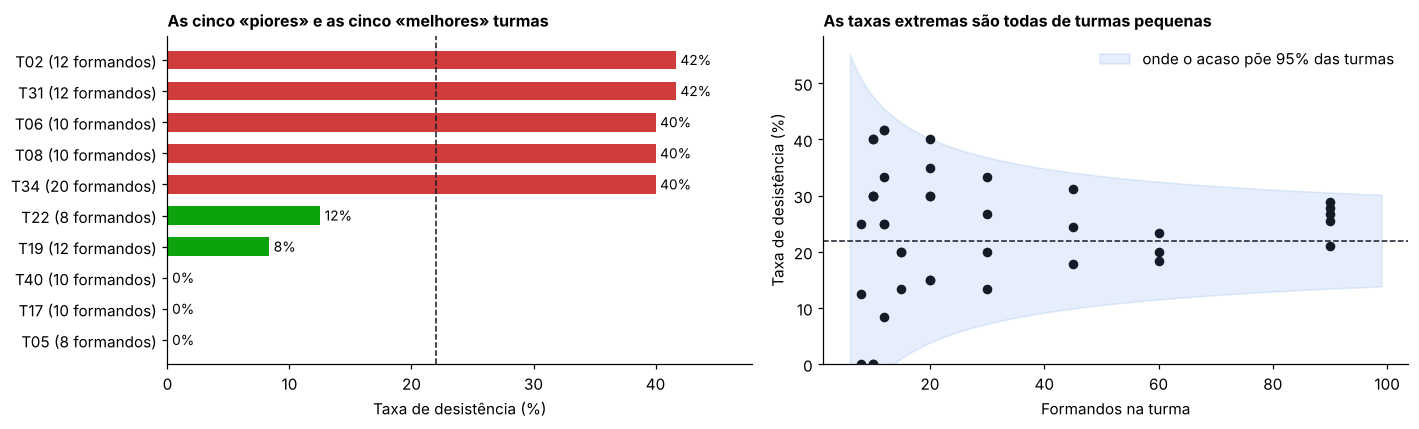

In [8]:
rng = np.random.default_rng(12)
tamanhos = rng.choice([8, 10, 12, 15, 20, 30, 45, 60, 90], 40)
desistencias = rng.binomial(tamanhos, 0.22)
turmas = pd.DataFrame({"turma": [f"T{i:02d}" for i in range(1, 41)], "formandos": tamanhos, "taxa": desistencias / tamanhos * 100})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
piores = turmas.nlargest(5, "taxa")
melhores = turmas.nsmallest(5, "taxa")
extremos = pd.concat([piores, melhores.iloc[::-1]])
barras = ax1.barh(extremos["turma"] + " (" + extremos["formandos"].astype(str) + " formandos)", extremos["taxa"], color=[MAU] * 5 + [BOM] * 5, height=0.6)
ax1.bar_label(barras, fmt="%.0f%%", padding=3, fontsize=9)
ax1.axvline(22, color=TINTA, ls="--", lw=1)
ax1.invert_yaxis()
ax1.set_xlim(0, extremos["taxa"].max() * 1.15)
ax1.set_xlabel("Taxa de desistência (%)")
ax1.set_title("As cinco «piores» e as cinco «melhores» turmas", fontsize=10.5)

n = np.arange(6, 100)
erro = np.sqrt(0.22 * 0.78 / n) * 100
ax2.fill_between(n, 22 - 1.96 * erro, 22 + 1.96 * erro, color=AZUL, alpha=0.12, label="onde o acaso põe 95% das turmas")
ax2.scatter(turmas["formandos"], turmas["taxa"], s=28, color=TINTA, zorder=3)
ax2.axhline(22, color=TINTA, ls="--", lw=1)
ax2.set_xlabel("Formandos na turma")
ax2.set_ylabel("Taxa de desistência (%)")
ax2.set_ylim(0, None)
ax2.set_title("As taxas extremas são todas de turmas pequenas", fontsize=10.5)
ax2.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

Todas as turmas têm o mesmo risco verdadeiro, e a tabela da esquerda parece mostrar turmas problemáticas e turmas exemplares. O gráfico da direita explica: as taxas mais altas **e** as mais baixas são todas de turmas pequenas. Numa turma de 10 formandos, uma desistência a mais ou a menos muda a taxa em 10 pontos.

O funil azul é a zona onde o acaso, sozinho, põe 95% das turmas. Só uma turma **fora** do funil merece atenção, e mesmo assim, em 40 turmas, espera-se que duas saiam por acaso.

> **Antes de ordenar grupos por uma taxa, olha para o tamanho de cada grupo.** Uma classificação de escolas, hospitais ou turmas feita só com taxas premeia e castiga, sobretudo, os mais pequenos.

O que apresentar em vez da tabela dos «cinco piores»: o gráfico em funil, ou a tabela com o número de casos e o intervalo de cada taxa, ou apenas os grupos que saem do funil.

## A incerteza de uma previsão individual

Há duas incertezas diferentes num modelo de classificação, e convém não as misturar.

| | Incerteza sobre o modelo | Incerteza sobre o caso |
| --- | --- | --- |
| Pergunta | Quão bem conhecemos o desempenho? | O que vai acontecer a este formando? |
| Diminui com | Mais dados | Melhores atributos (e nunca desaparece) |
| Exprime-se com | Um intervalo à volta da métrica | Uma probabilidade |

«Este formando tem um risco de 30%» **não quer dizer** que o modelo tem 30% de confiança, nem que o formando vai desistir «um bocadinho». Quer dizer: **entre os formandos parecidos com este, cerca de 3 em cada 10 desistem**. Para a frase ser verdadeira, o modelo tem de estar **calibrado** (módulo 5, capítulo 3).

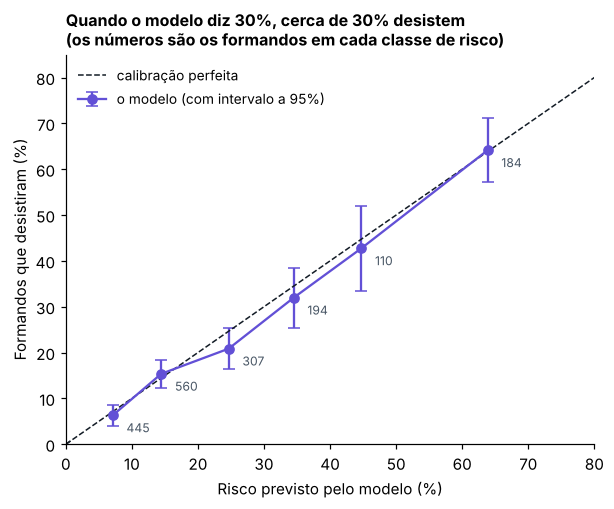

In [9]:
classes = pd.cut(risco, [0, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0])
calibracao = pd.DataFrame({"risco": risco, "real": real}).groupby(classes, observed=True).agg(previsto=("risco", "mean"), observado=("real", "mean"), n=("real", "size"))
erro = 1.96 * np.sqrt(calibracao["observado"] * (1 - calibracao["observado"]) / calibracao["n"])

fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.plot([0, 0.8], [0, 0.8], color=TINTA, ls="--", lw=1, label="calibração perfeita")
ax.errorbar(calibracao["previsto"] * 100, calibracao["observado"] * 100, yerr=erro * 100, fmt="o-", color=VIOLETA, capsize=4, label="o modelo (com intervalo a 95%)")
ax.plot([0, 80], [0, 80], color=TINTA, ls="--", lw=1)
for (_, linha) in calibracao.iterrows():
    ax.annotate(f"{int(linha['n'])}", (linha["previsto"] * 100, linha["observado"] * 100), textcoords="offset points", xytext=(9, -11), fontsize=8, color="#465463")
ax.set_xlim(0, 80)
ax.set_ylim(0, 85)
ax.set_xlabel("Risco previsto pelo modelo (%)")
ax.set_ylabel("Formandos que desistiram (%)")
ax.set_title("Quando o modelo diz 30%, cerca de 30% desistem\n(os números são os formandos em cada classe de risco)", fontsize=10.5)
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.show()

Os pontos acompanham a diagonal: o risco previsto corresponde ao que acontece. As barras alargam nas classes de risco alto, onde há poucos formandos.

Para quem recebe a lista, a frase deve vir em frequências, como no capítulo 1:

| Em vez de | Escrever |
| --- | --- |
| «Risco: 0,31» | «Em cada 10 formandos com este perfil, cerca de 3 desistem» |
| «Vai desistir» | «Risco alto: mais de metade dos formandos com este perfil desistem» |
| «Não está em risco» | «Risco baixo: desiste cerca de 1 em cada 15» (ninguém tem risco zero) |

## Como mostrar a incerteza

| Situação | Forma | Exemplo |
| --- | --- | --- |
| Um número num texto | Intervalo arredondado, com palavras | «cerca de 10 (entre 9 e 12)» |
| Vários valores num gráfico | Barras de erro ou faixa | os dois gráficos acima |
| Uma previsão ao longo do tempo | Faixa que alarga | «entre 40 e 60 desistências no próximo ano» |
| Uma comparação | O intervalo da **diferença** | «um caso a mais (entre zero e dois)» |
| Uma probabilidade | Frequência natural | «3 em cada 10» |
| Grupos de tamanhos diferentes | Funil, ou intervalo por grupo | o gráfico das turmas |

Três regras de escrita:

1. **Arredondar à margem.** Se o intervalo vai de 9 a 12, escrever «10», e não «10,4». As casas decimais devem parar onde começa a incerteza.
2. **Dizer o que é o intervalo.** «Entre 9 e 12» sem mais nada não diz se é o mínimo e o máximo, ou um intervalo a 95%. Uma nota basta: «intervalo que contém o valor verdadeiro em 19 de cada 20 casos como este».
3. **Não esconder um intervalo largo.** Um intervalo largo é um resultado: diz que os dados não chegam para concluir, e essa é muitas vezes a informação mais útil.

As palavras também transmitem probabilidades, de forma menos fiável: «provável» quer dizer 60% para uns e 90% para outros. Quando a decisão depende do valor, escreve-se o número ao lado da palavra: «provável (cerca de 3 em cada 4)».

## O que o intervalo não cobre

Um intervalo de confiança mede uma coisa só: a variação devida a ter **uma amostra e não outra**, tirada da mesma população. Não cobre os erros que costumam ser maiores.

| Fonte de erro | O intervalo cobre? | Onde se trata |
| --- | --- | --- |
| A amostra de teste é pequena | **Sim** | Este capítulo |
| Os formandos do próximo ano são diferentes dos de teste | Não | Capítulo 4 (monitorização) |
| Os dados têm erros de registo | Não | Módulo 2, capítulo 4 |
| O alvo mede outra coisa (desistências registadas ≠ desistências reais) | Não | Módulo 1, capítulo 4 |
| O teste foi usado para escolher o modelo | Não | Módulo 6, capítulo 6 |
| A associação não é causal: acompanhar pode não evitar a desistência | Não | Módulo 1, capítulos 2 e 5 |

Um intervalo estreito à volta de um número enviesado dá uma falsa sensação de rigor. Por isso o relatório do capítulo 1 tinha, além dos números, uma secção de **limites** escrita em palavras: é aí que cabem as incertezas que nenhum cálculo mede.

## Exercícios

### `Exercício 1` – Ler intervalos

Dois modelos foram avaliados no mesmo teste. O modelo A tem uma exatidão de 84% (intervalo a 95%: 81% a 87%); o modelo B tem 86% (83% a 89%). Um colega conclui que «o B é melhor». O que respondes? Que cálculo pedirias?

<details>
<summary><b>Ver uma solução possível</b></summary>

Os dois intervalos sobrepõem-se quase por completo: com estes dados, não se pode afirmar que B é melhor. Mas a sobreposição de dois intervalos isolados também não prova que são iguais.

Como os dois modelos foram avaliados **nos mesmos casos**, o cálculo certo é o intervalo da **diferença**, por bootstrap emparelhado (reamostrar as linhas e calcular B − A em cada amostra). Se os dois modelos acertam e erram quase nos mesmos casos, a diferença pode ter um intervalo estreito, e dois pontos podem ser uma vantagem real. Se o intervalo da diferença incluir o zero, a escolha faz-se por outros critérios: simplicidade, custo, facilidade de explicar.

</details>

### `Exercício 2` – Um intervalo para a AUC

Usa a função `bootstrap` para calcular um intervalo a 95% para a AUC do modelo no teste. Repete só com os formandos da zona rural. Porque é que o segundo intervalo é mais largo?

In [10]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.metrics import roc_auc_score

auc = lambda risco, real: roc_auc_score(real, risco)
for nome, filtro in [("todos", np.ones(len(teste), dtype=bool)), ("zona rural", (teste["zona"] == "rural").to_numpy())]:
    v = bootstrap(auc, risco[filtro], real[filtro], repeticoes=1000)
    print(f"{nome:>10} ({filtro.sum()} formandos): AUC {auc(risco[filtro], real[filtro]):.3f} | intervalo a 95%: {np.percentile(v, 2.5):.3f} a {np.percentile(v, 97.5):.3f}")
```

O intervalo da zona rural é bastante mais largo do que o geral: há quatro vezes menos formandos, e a largura cresce com o inverso da raiz quadrada do número de casos. É um problema geral quando se avalia um modelo por subgrupos (capítulo 5): quanto mais pequeno o grupo, menos se sabe sobre o desempenho do modelo nele, e é muitas vezes nos grupos pequenos que mais importa saber.

</details>

### `Exercício 3` – A turma «pior»

Na simulação das turmas, a turma com a taxa mais alta tem poucos formandos. Calcula a probabilidade de uma turma de 10 formandos, com um risco verdadeiro de 22%, ter 5 ou mais desistências. E a de uma turma de 60 ter 30 ou mais (os mesmos 50%). Usa `scipy.stats.binom`.

In [11]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from scipy.stats import binom

print(f"Turma de 10, 5 ou mais desistências: {binom.sf(4, 10, 0.22):.1%}")
print(f"Turma de 60, 30 ou mais desistências: {binom.sf(29, 60, 0.22):.5%}")
```

Numa turma de 10, uma taxa de 50% ou mais acontece por puro acaso em cerca de 5% dos casos: entre vinte turmas pequenas, é de esperar ver uma assim. Numa turma de 60, a mesma taxa é praticamente impossível por acaso. A mesma percentagem é um acidente num caso e um sinal forte no outro.

</details>

### `Exercício 4` – Reescrever com incerteza

Reescreve cada frase para a diretora do centro, com a incerteza dita de forma útil.

1. «A sensibilidade do modelo é 46,2%.»
2. «O curso de eletricidade tem a pior taxa de desistência: 40%.» (O curso tem 10 formandos.)
3. «Prevemos 135 desistências no próximo ano.»

<details>
<summary><b>Ver uma solução possível</b></summary>

1. «A lista apanha quase metade das desistências: cerca de 10 em cada 22, mais ou menos uma.»
2. «No curso de eletricidade desistiram 4 de 10 formandos. Com tão poucos, não se distingue de um curso com a taxa média; convém olhar para dois ou três anos antes de concluir.»
3. «Com o número de formandos previsto, esperamos entre 115 e 155 desistências no próximo ano, se nada mudar.» (Com cerca de 600 formandos e uma taxa de 22%, o acaso dá, sozinho, uma margem de cerca de 20 para cada lado; e «se nada mudar» é a reserva mais importante.)

</details>

## Verifica o que aprendeste

- [ ] Sei porque uma métrica calculada num teste é uma estimativa.
- [ ] Sei calcular um intervalo por bootstrap para qualquer métrica.
- [ ] Sei o que acontece à margem quando a amostra é pequena.
- [ ] Sei comparar dois modelos com o intervalo da diferença.
- [ ] Sei porque uma classificação de grupos pequenos engana.
- [ ] Sei explicar o que significa um risco de 30%.
- [ ] Sei escrever um número com a sua margem.
- [ ] Sei o que um intervalo de confiança não cobre.

## Leitura recomendada

- https://en.wikipedia.org/wiki/Bootstrapping_(statistics)
- https://en.wikipedia.org/wiki/Funnel_plot
- https://en.wikipedia.org/wiki/Calibration_(statistics)
- https://scikit-learn.org/stable/modules/calibration.html